# GDR 1565 — Neubrex DTS, Well 16B(78)-32, July 2023 Circulation Test

Reads the Neubrex DTS data from [GDR 1565](https://gdr.openei.org/submissions/1565) (DOI 10.15121/2222469) into
`JIN_pylib` `Data2D` objects and plots temperature waterfalls.

**Files** (`/data2/FORGE/data/2023-07_circulation/GDR1565_Neubrex_DAS_DSS_DTS_FBE_data/Neubrex/`):

| File | Period (local, UTC−06:00) | Content |
|---|---|---|
| `... DTS - mmf 2 - evo 0.h5` | Jul 13 01:13 – Jul 14 11:13, 2023 | Cementing / post-cementing |
| `... DTS - mmf 2 - evo 1.h5` | Jul 15 12:18 – Jul 20 15:40, 2023 | Circulation test period |

**HDF5 layout** (per Neubrex transmittal document): `data` (n_time × n_depth, °F), `depth` (ft MD),
`stamps` (local-time strings, UTC−06:00), `stamps_unix` (µs since epoch, UTC).
Multimode fiber (mmf 2), ~3.32 ft spatial sampling, ~257 s per trace.

**Conventions used here:** times are converted to **UTC** from `stamps_unix` (subtract 6 h for local time in the
Neubrex reports). The fiber ends at ≈10,110 ft MD; samples below 10,100 ft (fiber-end artifacts and excess fiber at
surface) are cropped. Traces with non-physical temperatures (instrument dropouts) are removed.

In [1]:
import sys
sys.path.append('/data2/FORGE')   # parent dir of the JIN_pylib clone (github.com/jinwar/jin_pylib)

from datetime import datetime, timezone
import numpy as np
import h5py
import matplotlib.pyplot as plt
from JIN_pylib import Data2D_XT

%matplotlib inline

In [2]:
DATADIR = '/data2/FORGE/data/2023-07_circulation/GDR1565_Neubrex_DAS_DSS_DTS_FBE_data/Neubrex'
FILES = {
    'evo0': f'{DATADIR}/Utah Forge 16B(78)-32 - DTS - mmf 2 - evo 0.h5',
    'evo1': f'{DATADIR}/Utah Forge 16B(78)-32 - DTS - mmf 2 - evo 1.h5',
}
WELL_BOTTOM_FT = 10100   # last good in-well sample; fiber end/turnaround artifacts below (MD, ft)

## Reader: Neubrex DTS HDF5 → `Data2D`

In [3]:
def read_neubrex_dts(filename):
    """Read a Neubrex DTS HDF5 file into a Data2D (depth x time), times in UTC."""
    with h5py.File(filename, 'r') as f:
        data = f['data'][:].T                    # -> (n_depth, n_time)
        depth = f['depth'][:].astype(float)
        stamps_us = f['stamps_unix'][:]
        attrs = {k: (v.decode() if isinstance(v, bytes) else v) for k, v in f['data'].attrs.items()}

    timestamps = [datetime.fromtimestamp(t / 1e6, tz=timezone.utc).replace(tzinfo=None) for t in stamps_us]

    DASdata = Data2D_XT.Data2D()
    DASdata.set_data(data)
    DASdata.set_time_from_datetime(timestamps)
    DASdata.daxis = depth
    DASdata.chans = np.arange(len(depth))
    DASdata.attrs.update(attrs)
    DASdata.attrs['source_file'] = filename
    DASdata.attrs['time_zone'] = 'UTC'
    DASdata.history.append('read_neubrex_dts: transposed to depth x time, time from stamps_unix (UTC)')
    return DASdata

In [4]:
dts = {key: read_neubrex_dts(fn) for key, fn in FILES.items()}
for key, d in dts.items():
    print(f'--- {key}')
    d.print_info()

--- evo0
Start time: 2023-07-13 07:13:57
taxis: 0.0 - 122398.0 seconds
time interval: min: 256.0, max: 5174.0, median: 257.0
daxis: -0.28717041015625 - 20639.046875
data dimension: (6183, 458)
data size: 11 MB
taxis dimension: (458,)
daxis dimension: (6183,)
history: ['read_neubrex_dts: transposed to depth x time, time from stamps_unix (UTC)']
--- evo1
Start time: 2023-07-15 18:18:01
taxis: 0.0 - 444138.0 seconds
time interval: min: 256.0, max: 2478.0, median: 257.0
daxis: -0.334625244140625 - 20714.39453125
data dimension: (6214, 1720)
data size: 42 MB
taxis dimension: (1720,)
daxis dimension: (6214,)
history: ['read_neubrex_dts: transposed to depth x time, time from stamps_unix (UTC)']


## Crop to the in-well section

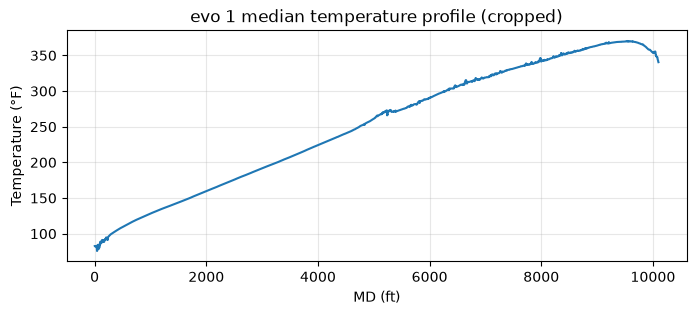

In [5]:
for d in dts.values():
    d.select_depth(0, WELL_BOTTOM_FT)

# quick look at the depth cut: median profile around the end of the in-well fiber
d = dts['evo1']
plt.figure(figsize=(8, 3))
plt.plot(d.daxis, np.median(d.data, axis=1))
plt.xlabel('MD (ft)'); plt.ylabel('Temperature (°F)')
plt.title('evo 1 median temperature profile (cropped)')
plt.grid(alpha=0.3)
plt.show()

## QC: remove dropout traces

A few traces read non-physical temperatures (median below 0 °F) along the whole well. They are dropped.

In [6]:
def drop_bad_traces(d, min_temp=0.0):
    """Drop traces whose median in-well temperature is below min_temp (°F)."""
    med = np.median(d.data, axis=0)
    bad = med < min_temp
    times = np.array(d.get_datetime())
    for t, m in zip(times[bad], med[bad]):
        print(f'  dropping trace at {t} UTC (median {m:.1f} °F)')
    if bad.any():
        d.data = d.data[:, ~bad]
        d.taxis = d.taxis[~bad]
        d.history.append(f'drop_bad_traces: removed {bad.sum()} traces with median < {min_temp} °F')
    return d

for key, d in dts.items():
    print(key)
    drop_bad_traces(d)

evo0
evo1
  dropping trace at 2023-07-18 06:34:15 UTC (median -28.8 °F)
  dropping trace at 2023-07-18 12:38:26 UTC (median -24.3 °F)


## Waterfall — circulation test period (evo 1)

Absolute temperature, Jul 15–20, 2023.

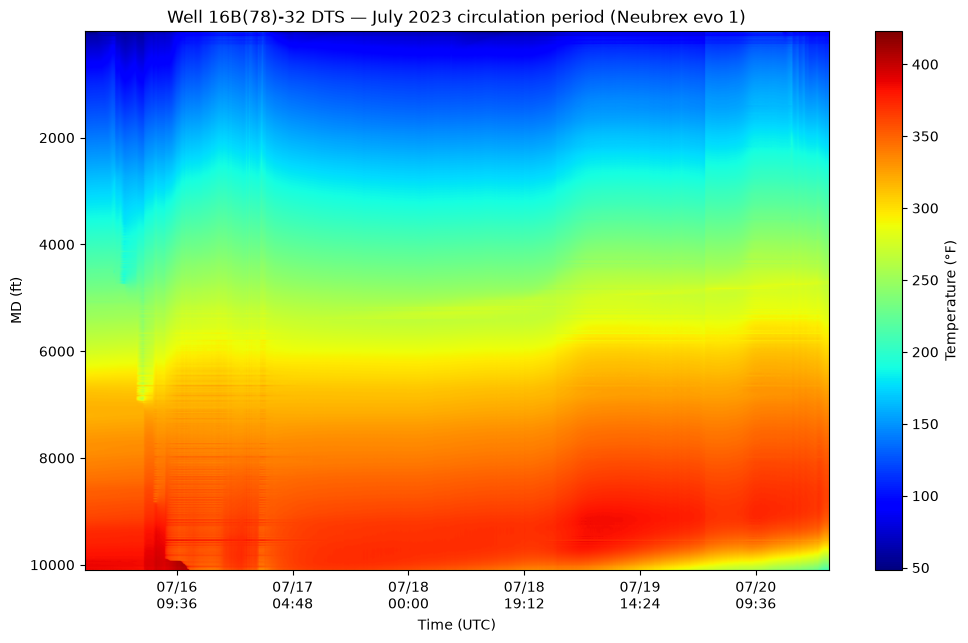

In [7]:
d = dts['evo1']
plt.figure(figsize=(12, 7))
d.plot_waterfall(cmap='jet', use_timestamp=True, timefmt='%m/%d\n%H:%M', xtickN=8)
plt.colorbar(label='Temperature (°F)')
plt.ylabel('MD (ft)')
plt.xlabel('Time (UTC)')
plt.title('Well 16B(78)-32 DTS — July 2023 circulation period (Neubrex evo 1)')
plt.show()

## Waterfall — temperature change relative to the first trace (evo 1)

Subtracting the first trace removes the geothermal gradient and highlights cooling/warming during circulation.

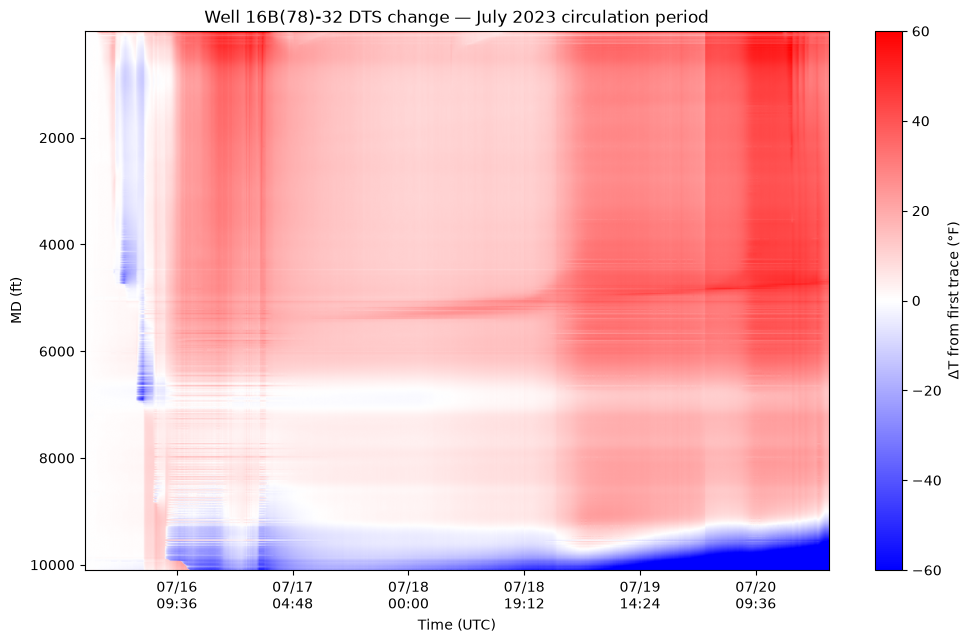

In [8]:
d_change = dts['evo1'].copy()
d_change.data = d_change.data - d_change.data[:, [0]]
d_change.history.append('subtract first trace (baseline)')

plt.figure(figsize=(12, 7))
d_change.plot_waterfall(cmap='bwr', use_timestamp=True, timefmt='%m/%d\n%H:%M', xtickN=8, scale=[-60, 60])
plt.colorbar(label='ΔT from first trace (°F)')
plt.ylabel('MD (ft)')
plt.xlabel('Time (UTC)')
plt.title('Well 16B(78)-32 DTS change — July 2023 circulation period')
plt.show()

## Waterfall — cementing period (evo 0)

Jul 13–14, 2023, for reference.

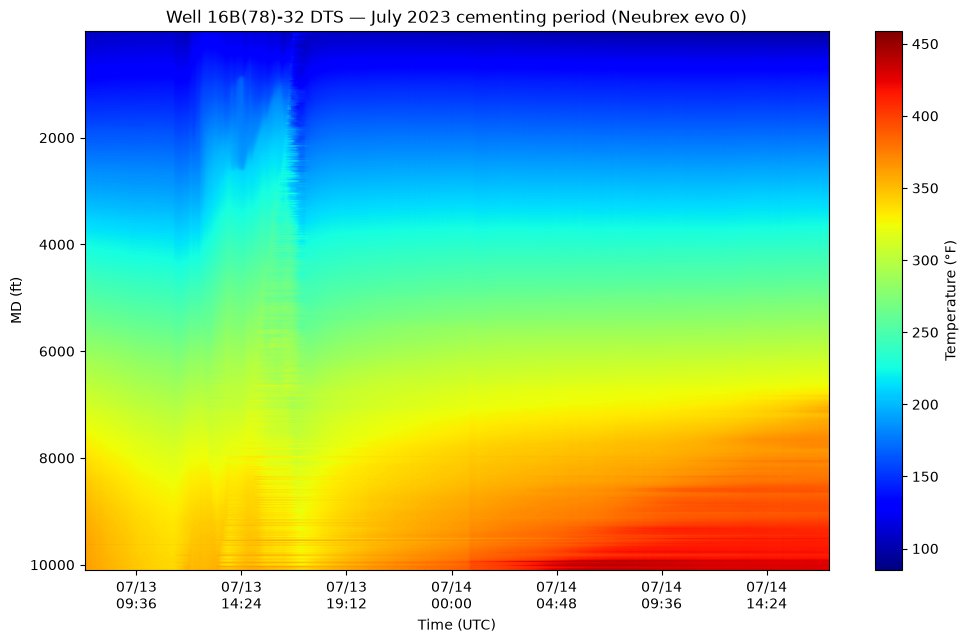

In [9]:
d = dts['evo0']
plt.figure(figsize=(12, 7))
d.plot_waterfall(cmap='jet', use_timestamp=True, timefmt='%m/%d\n%H:%M', xtickN=8)
plt.colorbar(label='Temperature (°F)')
plt.ylabel('MD (ft)')
plt.xlabel('Time (UTC)')
plt.title('Well 16B(78)-32 DTS — July 2023 cementing period (Neubrex evo 0)')
plt.show()